# Stage 1: reproduce Kandpal et al. on Enron (GPT-Neo 125M)
**Gate (plan section 4):** T̂ AUROC near Kandpal's 0.873, and the null model ≈ chance. Otherwise debug; do not proceed.

**Getting the results:** at the end of a Kaggle run, download `/kaggle/working/outputs/S1_<time>.tar.gz` and extract
it into `Stage1/results/`, which is git-ignored. Every `scores*.csv.gz` and `history_*.json` under it is loaded
(several runs and seeds can sit side by side). This notebook needs no GPU.

In [1]:
import os, sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath(".."))
import analysis as A
RESULTS = os.environ.get("S1_RESULTS", "results")   # folder holding the extracted Kaggle archive(s)
R_DRAWS = 200                  # random draws of m docs per user, for m < 32
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
df, hist = A.load(RESULTS)
summary = df.groupby(["run", "seed"]).agg(docs=("doc_id", "size"), users=("user", "nunique"),
                                         best_epoch=("best_epoch", "first"), model=("model", "first"))
summary["trained_users"] = df[df.trained == 1].groupby(["run", "seed"]).user.nunique()
print(summary)

           docs  users  best_epoch                    model  trained_users
run  seed                                                                 
main 0     5600    175           2  EleutherAI/gpt-neo-125m             82
null 0     5600    175           2  EleutherAI/gpt-neo-125m             45


## 1. Training: validation loss by epoch
`val_in` = members' validation docs (selects the best epoch). `val_out` = non-members' validation docs. The gap between the two is the user-level generalisation gap, E[Δ] (plan Step B.2).

,run,epoch,train_loss,val_in,val_out,min,best
0,main_s0,0,NaN,3.2836,3.4828,0.0000,False
1,main_s0,1,2.6519,2.5065,3.1913,15.6340,False
2,main_s0,2,2.3178,2.4530,3.2016,15.6559,True
3,main_s0,3,2.1186,2.4542,3.2660,15.6440,False
4,main_s0,4,1.9475,2.4836,3.3532,15.6324,False
5,main_s0,5,1.7887,2.5402,3.4719,15.6236,False
6,main_s0,6,1.6461,2.6125,3.5960,15.5931,False
7,main_s0,7,1.5139,2.6772,3.7073,15.6251,False
8,main_s0,8,1.4022,2.7567,3.8287,15.5926,False
9,main_s0,9,1.3077,2.8215,3.9292,15.6007,False


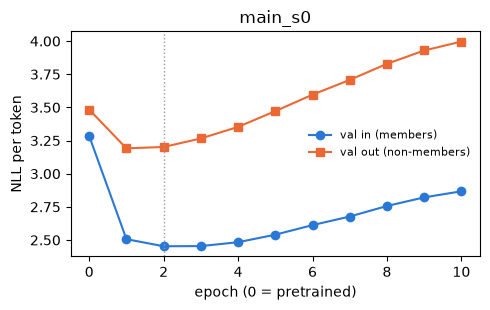

In [2]:
H = A.history_table(hist)
display(H.round(4))
fig, axes = plt.subplots(1, max(1, H.run.nunique()), figsize=(5 * max(1, H.run.nunique()), 3.2), squeeze=False)
for ax, (tag, h) in zip(axes[0], H.groupby("run")):
    ax.plot(h.epoch, h.val_in, "o-", color=C1, label="val in (members)")
    ax.plot(h.epoch, h.val_out, "s-", color=C2, label="val out (non-members)")
    b = h[h.best]; ax.axvline(b.epoch.iloc[0], color="0.6", ls=":", lw=1)
    ax.set(title=tag, xlabel="epoch (0 = pretrained)", ylabel="NLL per token"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 2. Score sanity
The mean s(x) should be clearly higher for trained users than for untrained ones (main run). In the null run, EVAL users are all untrained, so their fake labels b should show no gap.

In [3]:
print(df.groupby(["run", "seed", "trained"]).agg(docs=("s", "size"), mean_s=("s", "mean"), sd_s=("s", "std"),
      mean_tokens=("n_tokens", "mean")).round(3))
print("\nnull run, EVAL users, by fake label b:")
print(df[(df.run == "null") & (df.half == "EVAL")].groupby(["seed", "b"]).s.agg(["size", "mean"]).round(3))

                   docs  mean_s    sd_s  mean_tokens
run  seed trained                                   
main 0    0        2976  12.152  42.014       66.505
          1        2624  62.246  82.279       70.215
null 0    0        4160   6.843  45.321       67.896
          1        1440  68.331  95.620       69.247

null run, EVAL users, by fake label b:
        size    mean
seed b              
0    0  1632  10.426
     1  1184   6.902


## 3. Main run: T̂ AUROC vs m, certificates
Rows are averaged over the R draws of m documents per user (one score per user per draw). `dkw_threshold` = Ĵ needed for a positive certificate with these n1, n0 (Cor. 1). `tpr_1pct_below_1_over_n0 = True` means TPR at 1% FPR rests on fewer than one false positive, so it is not a certified rate.

seed 0


,m,n1,n0,draws,auroc,auroc_lo,auroc_hi,j_hat,dkw_cert,dkw_cert_positive_frac,j_from_auroc,tpr_at_1pct,tpr_1pct_below_1_over_n0,dkw_threshold,users_needed_per_class
0,1,82,93,200,0.742,0.689,0.796,0.402,0.085,0.955,0.282,0.147,True,0.317,54.327
1,2,82,93,200,0.784,0.731,0.836,0.464,0.147,0.995,0.342,0.164,True,0.317,40.752
2,4,82,93,200,0.822,0.782,0.860,0.525,0.208,1.000,0.403,0.162,True,0.317,31.837
3,8,82,93,200,0.850,0.828,0.871,0.573,0.256,1.000,0.453,0.166,True,0.317,26.667
4,16,82,93,200,0.869,0.854,0.885,0.614,0.297,1.000,0.488,0.172,True,0.317,23.247
5,32,82,93,1,0.881,0.881,0.881,0.667,0.350,1.000,0.512,0.207,True,0.317,19.727


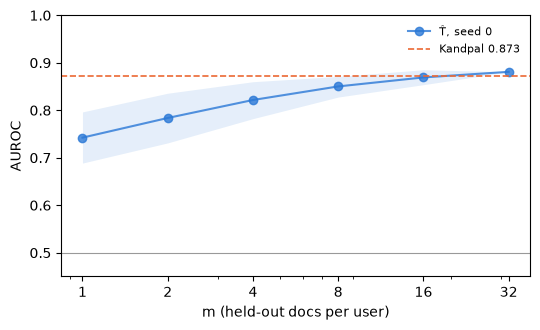

In [4]:
main = {s: d for s, d in df[df.run == "main"].groupby("seed")}
rows = {s: A.auroc_vs_m(d, R=R_DRAWS) for s, d in main.items()}
for s, r in rows.items():
    print(f"seed {s}"); display(r.round(3))
fig, ax = plt.subplots(figsize=(5.5, 3.4))
for s, r in rows.items():
    ax.plot(r.m, r.auroc, "o-", color=C1, alpha=.8, label=f"T̂, seed {s}")
    ax.fill_between(r.m, r.auroc_lo, r.auroc_hi, color=C1, alpha=.12, lw=0)
ax.axhline(A.KANDPAL_AUROC, color=C2, ls="--", lw=1.2, label="Kandpal 0.873")
ax.axhline(.5, color="0.6", lw=.8)
ax.set(xscale="log", xticks=A.M_GRID, xticklabels=A.M_GRID, xlabel="m (held-out docs per user)", ylabel="AUROC", ylim=(.45, 1))
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

In [5]:
for s, d in main.items():
    r = A.report_m32(d)
    print(f"seed {s}, m = 32:", {k: (np.round(v, 3).tolist() if isinstance(v, (list, float)) else v) for k, v in r.items()})

seed 0, m = 32: {'n1': 82, 'n0': 93, 'auroc': 0.881, 'auroc_ci': [0.828, 0.928], 'j_hat': 0.667, 'j_threshold': 26.109, 'dkw_cert': 0.35, 'eta': 0.05, 'tpr_at_1pct': 0.207, 'tpr_at_1pct_below_1_over_n0': True, 'tpr_at_0.1pct': 0.11, 'tpr_at_0.1pct_below_1_over_n0': True, 'users_needed_per_class': 19.727}


## 4. Null model (EVAL users only; their labels are fake)
Every statistic must show J ≈ 0 here (plan Step B.4).

In [6]:
null = {s: d[d.half == "EVAL"] for s, d in df[df.run == "null"].groupby("seed")}
if not null:
    print("no null run yet")
for s, d in null.items():
    print(f"null seed {s}"); display(A.auroc_vs_m(d, R=R_DRAWS).round(3))

null seed 0


,m,n1,n0,draws,auroc,auroc_lo,auroc_hi,j_hat,dkw_cert,dkw_cert_positive_frac,j_from_auroc,tpr_at_1pct,tpr_1pct_below_1_over_n0,dkw_threshold,users_needed_per_class
0,1,37,51,200,0.515,0.418,0.608,0.136,-0.315,0.0,0.015,0.007,True,0.451,475.397
1,2,37,51,200,0.529,0.451,0.614,0.155,-0.296,0.0,0.029,0.011,True,0.451,366.378
2,4,37,51,200,0.536,0.465,0.609,0.166,-0.285,0.0,0.037,0.005,True,0.451,317.968
3,8,37,51,200,0.545,0.488,0.589,0.175,-0.276,0.0,0.046,0.001,True,0.451,286.329
4,16,37,51,200,0.551,0.517,0.587,0.190,-0.261,0.0,0.052,0.000,True,0.451,242.535
5,32,37,51,1,0.559,0.559,0.559,0.194,-0.256,0.0,0.060,0.000,True,0.451,231.695


## 5. Gate verdict (automatic part)
At m = 32. "Near 0.873" means within ±0.05; that tolerance is our choice. The null passes if its 95% user-bootstrap CI contains 0.5 and its DKW certificate is ≤ 0.
**Caveat:** Kandpal et al.'s 0.873 may use a different number of documents per user than our m = 32. Compare the whole curve, not one point.

In [7]:
for s in main:
    g = A.gate(main[s], null.get(s))
    print(f"seed {s}:", {k: (np.round(v, 3).tolist() if isinstance(v, (list, float)) else v) for k, v in g.items()})

seed 0: {'auroc_m32': 0.881, 'auroc_m32_ci': [0.828, 0.928], 'kandpal': 0.873, 'tol': 0.05, 'main_ok': True, 'null_auroc_m32': 0.559, 'null_auroc_ci': [0.432, 0.678], 'null_dkw_cert': -0.256, 'null_ok': True}


## Notes (seed 0 pilot; written 2026-11-24)
**Status: CLOSED, gate passed.**

- **Training (best epoch, val gap):** 82 members, 42,946 training docs, 10 epochs at 15.6 min each (2.66 h in total on a T4).
  Best member validation at **epoch 2** (val_in 2.453; it was 3.284 before fine-tuning). From epoch 3, val_in rises: the model overfits early.
  Non-member validation also drops at epoch 1 (3.48 → 3.19) because the model learns the Enron domain, then rises.
- **T̂ AUROC vs m, compared with Kandpal:** 0.742 / 0.784 / 0.822 / 0.850 / 0.869 / **0.881** for m = 1 / 2 / 4 / 8 / 16 / 32.
  At m = 32 the user-bootstrap 95% CI is [0.828, 0.928]. Kandpal report 0.873: **reproduced**.
- **Certificates (main run, η = 0.05, n1 = 82, n0 = 93, DKW threshold 0.317):**
  - At m = 32, Ĵ = 0.667 and the DKW certificate is **+0.350**.
  - The certificate is positive at every m, including m = 1 (+0.085, positive in 96% of draws).
  - The AUROC → J bound (Prop. 2 iii) gives 0.512 ≤ Ĵ: consistent, but loose.
  - Users needed per class (Cor. 1): 54 at m = 1 and 20 at m = 32, so we have enough.
  - TPR at 1% FPR (0.21) is not meaningful, since n0 = 93 means 1% is under one user.
  - This is a pilot, not the pre-registered headline certificate.
- **Score sanity:**
  - Mean s is +62 for members and +12 for non-members: fine-tuning raises the likelihood of all Enron mail.
  - The three highest-scoring non-members are bulk senders (outlook.team, no.address, exchangeinfo@nymex), consistent with the cross-user template duplicates we chose to ignore.
- **Null model (45 FIT members trained on; 88 EVAL users never trained on, scored with fake labels 37 / 51):**
  - AUROC at m = 32 is 0.559, with CI [0.432, 0.678], which contains 0.5.
  - The DKW certificate at m = 32 is **−0.256**, and it is negative at every m in 100% of draws.
  - Positive control in the same run: FIT users with real labels give AUROC 0.926.
  - Reference scores are identical between the two runs (maximum difference 0).
  - The null-run archive is missing run.log, history and manifest; only the score table was kept.
- **Gate decision: PASSED.** The main AUROC is within ±0.05 of 0.873, and the null run is at chance with a certificate ≤ 0.
- **Decision for later stages (user, 2026-11-24):** fix the training at **4 epochs**, still keeping the best member-validation epoch. Seed 0 used 10, with its best at epoch 2.
  The learning-rate schedule decays over all epochs, so a 4-epoch run is not identical to this one.